In [1]:
"""
O que estamos fazendo?
- pandas: trabalhar com tabelas, chamadas de DataFrames.
- numpy: realizar cálculos numéricos.
- matplotlib: construir gráficos.
- seaborn: criar visualizações estatísticas.
"""
# carregando as bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### Explorando os Dados


In [2]:
# carregando o dataset diretamente pela URL (o CSV não vai para o repositório)
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)

# visualizar as primeiras linhas do dataset
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# verificar dimensões do dataset
df.shape


(284807, 31)

#### Investigar valores ausentes


In [4]:
# verificar os tipos de dados
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [5]:
# verificar estatísticas descritivas
df.describe()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.596686e-16,-3.576577e-16,2.618565e-16,4.473116e-15,5.109395e-16,1.686100e-15,-3.657409e-16,-1.221465e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [6]:
# verificar valores nulos por coluna
df.isnull().sum()


Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [7]:
# verificar se existe algum valor nulo no dataset
df.isnull().sum().sum()


np.int64(0)

In [8]:
# verificar a quantidade de transações fraudulentas e normais
df["Class"].value_counts()


Class
0    284315
1       492
Name: count, dtype: int64

In [9]:
# verificar a porcentagem de transações fraudulentas e normais
df["Class"].value_counts(normalize=True) * 100


Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

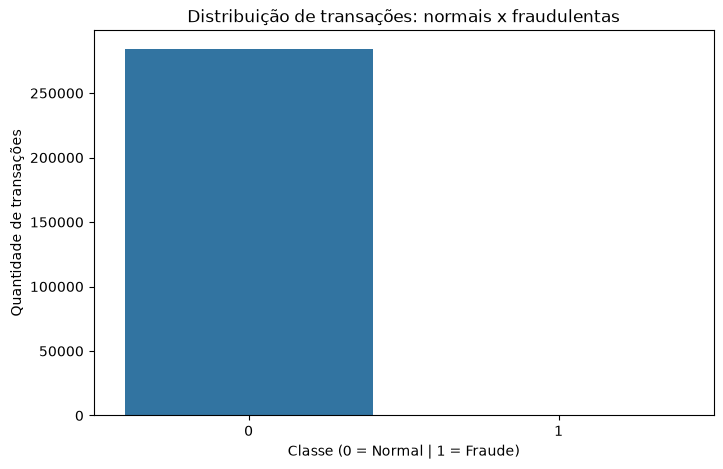

In [ ]:
# Visualizando a distribuição de transações fraudulentas e normais
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Class")

plt.title("Distribuição de transações: normais x fraudulentas")
plt.xlabel("Classe (0 = Normal | 1 = Fraude)")
plt.ylabel("Quantidade de transações")

plt.show()


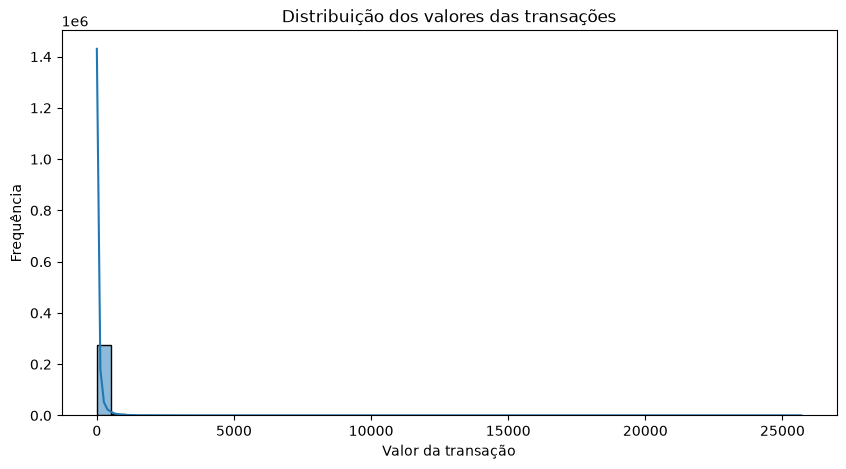

In [11]:
# Visualizando a distribuição dos valores das transações
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Amount", bins=50, kde=True)

plt.title("Distribuição dos valores das transações")
plt.xlabel("Valor da transação")
plt.ylabel("Frequência")

plt.show()


In [12]:
# Analisando estatísticas do valor das transações agrupadas por classe
df.groupby("Class")["Amount"].describe()


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


### Preparação dos dados


In [13]:
# Criando uma cópia do DataFrame original para modelagem
df_modelo = df.copy()


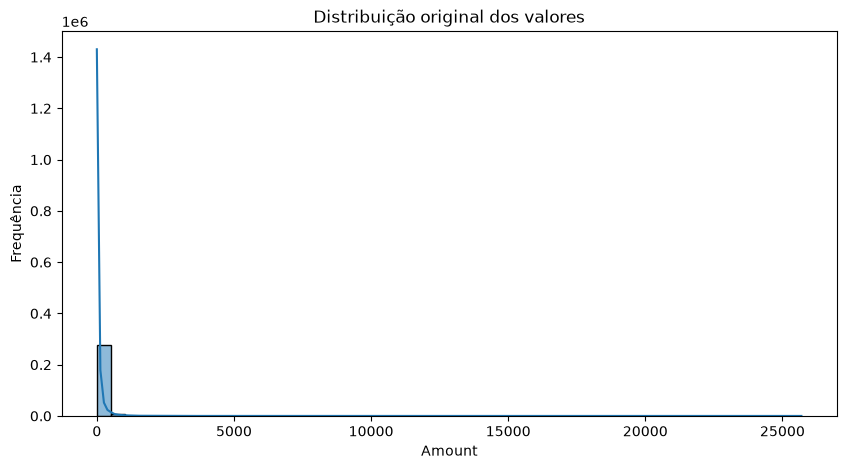

In [14]:
# Visualizando a distribuição original dos valores das transações
plt.figure(figsize=(10, 5))

sns.histplot(df_modelo["Amount"], bins=50, kde=True)

plt.title("Distribuição original dos valores")
plt.xlabel("Amount")
plt.ylabel("Frequência")

plt.show()


In [15]:
# Aplicando a transformação logarítmica para reduzir a assimetria da distribuição
df_modelo["Amount_log"] = np.log1p(df_modelo["Amount"])


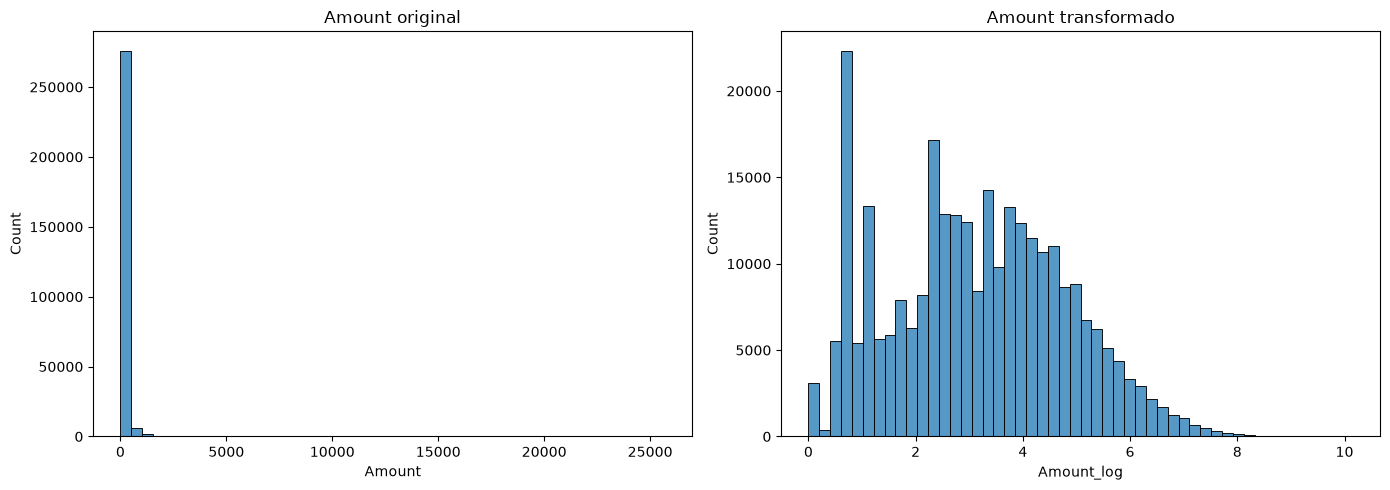

In [16]:
# Comparando a distribuição antes e depois da transformação logarítmica
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_modelo["Amount"], bins=50, ax=axes[0])
axes[0].set_title("Amount original")

sns.histplot(df_modelo["Amount_log"], bins=50, ax=axes[1])
axes[1].set_title("Amount transformado")

plt.tight_layout()
plt.show()


In [17]:
# Separando as features (X) e o target (y)
X = df_modelo.drop(columns=["Class", "Amount"])
y = df_modelo["Class"]

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)


Formato de X: (284807, 30)
Formato de y: (284807,)


- **X:** contém as características usadas para identificar padrões (`Time`, `V1`–`V28` e `Amount_log`).
- **y:** contém a resposta que queremos prever (`Class`).
- `Class` não pode ficar em `X`, pois isso causaria vazamento de informação (*data leakage*).
- `Amount` foi substituída por `Amount_log`.


In [18]:
from sklearn.model_selection import train_test_split

# primeira divisão: conjunto de teste fica separado até a avaliação final
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# segunda divisão: dentro do treino, separamos validação para escolher limiar e hiperparâmetros
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X_train, y_train, test_size=0.30, random_state=42, stratify=y_train
)

print("Treino interno:", X_treino.shape, "| fraudes:", int(y_treino.sum()))
print("Validação:", X_validacao.shape, "| fraudes:", int(y_validacao.sum()))
print("Teste (reservado):", X_test.shape, "| fraudes:", int(y_test.sum()))

print("\nProporção de fraudes:")
print("Treino interno:", round(y_treino.value_counts(normalize=True).loc[1] * 100, 4), "%")
print("Validação:", round(y_validacao.value_counts(normalize=True).loc[1] * 100, 4), "%")
print("Teste:", round(y_test.value_counts(normalize=True).loc[1] * 100, 4), "%")


Treino interno: (139554, 30) | fraudes: 241
Validação: (59810, 30) | fraudes: 103
Teste (reservado): (85443, 30) | fraudes: 148

Proporção de fraudes:
Treino interno: 0.1727 %
Validação: 0.1722 %
Teste: 0.1732 %


### Padronização dentro do Pipeline

Não vamos mais criar `X_train_scaled` / `X_test_scaled` manualmente. O `StandardScaler` passa a ser uma etapa do `Pipeline`, junto com o modelo. Assim o scaler é ajustado apenas nos dados de treino de cada divisão, e o mesmo objeto já aplica a transformação na validação e no teste. Isso evita vazamento de informação e torna a busca de hiperparâmetros mais simples.


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score,
    precision_score,
    f1_score,
    accuracy_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
)
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.base import clone

from xgboost import XGBClassifier


def construir_pipeline(modelo):
    """Junta padronização e classificador em um único estimador."""
    return Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", modelo),
    ])


construir_pipeline(LogisticRegression())


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio

In [20]:
# peso da fraude calculado apenas no conjunto de treino interno
qtd_normal = (y_treino == 0).sum()
qtd_fraude = (y_treino == 1).sum()

peso_fraude = qtd_normal / qtd_fraude

print("Transações normais:", qtd_normal)
print("Transações fraudulentas:", qtd_fraude)
print("Peso da classe fraude:", round(peso_fraude, 4))


Transações normais: 139313
Transações fraudulentas: 241
Peso da classe fraude: 578.0622


In [21]:
# baseline: regressão logística com peso balanceado
pipeline_lr = construir_pipeline(
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
)
pipeline_lr.fit(X_treino, y_treino)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Time','V1','V2',...,'V27','V28','Amount_log']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [22]:
# Random Forest com peso balanceado
pipeline_rf = construir_pipeline(
    RandomForestClassifier(
        n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1
    )
)
pipeline_rf.fit(X_treino, y_treino)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Time','V1','V2',...,'V27','V28','Amount_log']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [23]:
# XGBoost com peso explícito para a classe minoritária
pipeline_xgb = construir_pipeline(
    XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=peso_fraude,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,
    )
)
pipeline_xgb.fit(X_treino, y_treino)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Time','V1','V2',...,'V27','V28','Amount_log']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [24]:
def avaliar_modelo(nome, modelo, X_avaliacao, y_avaliacao, limiar=0.5):
    """Avalia um Pipeline usando probabilidades e um limiar de decisão."""
    probabilidades = modelo.predict_proba(X_avaliacao)[:, 1]
    previsoes = (probabilidades >= limiar).astype(int)

    return {
        "Modelo": nome,
        "Acurácia": accuracy_score(y_avaliacao, previsoes),
        "Precisão": precision_score(y_avaliacao, previsoes, zero_division=0),
        "Recall": recall_score(y_avaliacao, previsoes, zero_division=0),
        "F1-score": f1_score(y_avaliacao, previsoes, zero_division=0),
        "ROC-AUC": roc_auc_score(y_avaliacao, probabilidades),
        "Average Precision": average_precision_score(y_avaliacao, probabilidades),
    }


In [25]:
# comparação dos candidatos NA VALIDAÇÃO (o teste continua reservado)
modelos_validacao = {
    "Regressão Logística": pipeline_lr,
    "Random Forest": pipeline_rf,
    "XGBoost": pipeline_xgb,
}

df_validacao = pd.DataFrame([
    avaliar_modelo(nome, modelo, X_validacao, y_validacao)
    for nome, modelo in modelos_validacao.items()
])

df_validacao.sort_values(by="Recall", ascending=False).round(4)


,Modelo,Acurácia,Precisão,Recall,F1-score,ROC-AUC,Average Precision
0,Regressão Logística,0.9780,0.0683,0.9320,0.1272,0.9881,0.7759
2,XGBoost,0.9993,0.7672,0.8641,0.8128,0.9857,0.8791
1,Random Forest,0.9996,0.9149,0.8350,0.8731,0.9640,0.8786


In [26]:
for nome, modelo in modelos_validacao.items():
    previsoes = (modelo.predict_proba(X_validacao)[:, 1] >= 0.5).astype(int)

    print(f"\n{'=' * 50}")
    print(f"MODELO: {nome} (validação)")
    print(f"{'=' * 50}")
    print(classification_report(
        y_validacao, previsoes, target_names=["Normal", "Fraude"], zero_division=0
    ))



MODELO: Regressão Logística (validação)
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99     59707
      Fraude       0.07      0.93      0.13       103

    accuracy                           0.98     59810
   macro avg       0.53      0.96      0.56     59810
weighted avg       1.00      0.98      0.99     59810


MODELO: Random Forest (validação)
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     59707
      Fraude       0.91      0.83      0.87       103

    accuracy                           1.00     59810
   macro avg       0.96      0.92      0.94     59810
weighted avg       1.00      1.00      1.00     59810




MODELO: XGBoost (validação)
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     59707
      Fraude       0.77      0.86      0.81       103

    accuracy                           1.00     59810
   macro avg       0.88      0.93      0.91     59810
weighted avg       1.00      1.00      1.00     59810



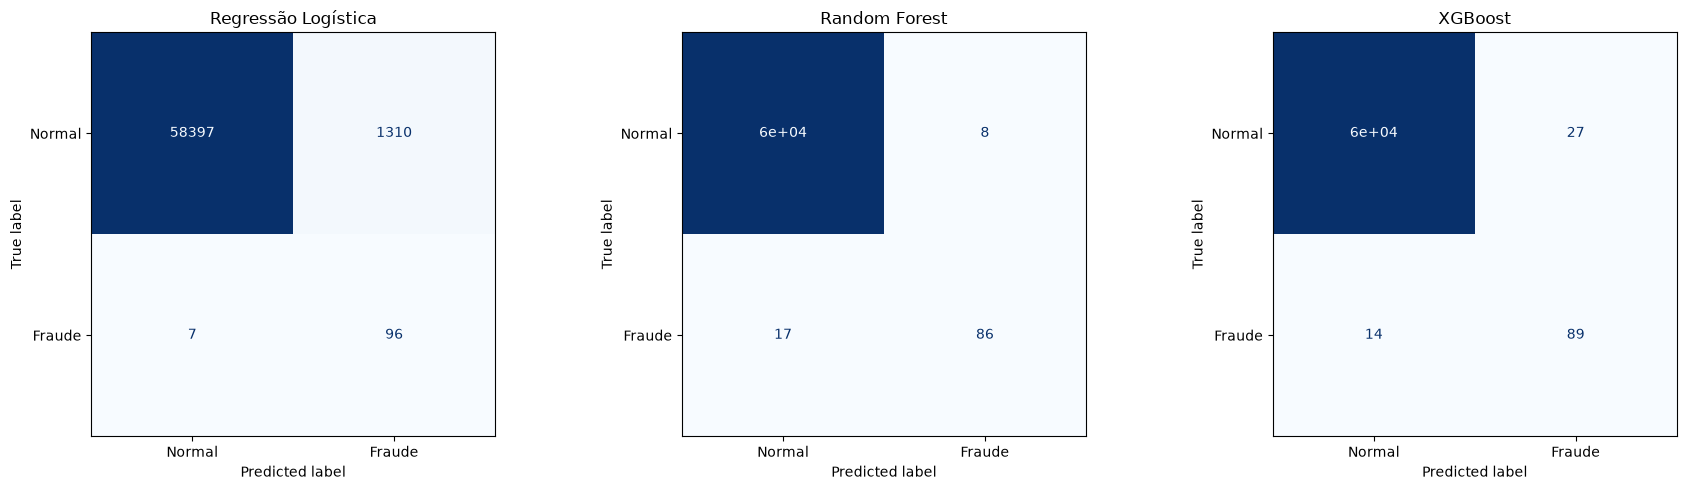

In [ ]:
# Visualizando as matrizes de confusão dos modelos na validação
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nome, modelo) in zip(axes, modelos_validacao.items()):
    previsoes = (modelo.predict_proba(X_validacao)[:, 1] >= 0.5).astype(int)

    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_validacao, previsoes),
        display_labels=["Normal", "Fraude"],
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(nome)

plt.tight_layout()
plt.show()


### Curvas ROC e Precision-Recall (validação)

As curvas abaixo usam as probabilidades dos modelos candidatos no conjunto de validação. A curva Precision-Recall merece mais atenção que a ROC porque a classe fraude é muito rara.


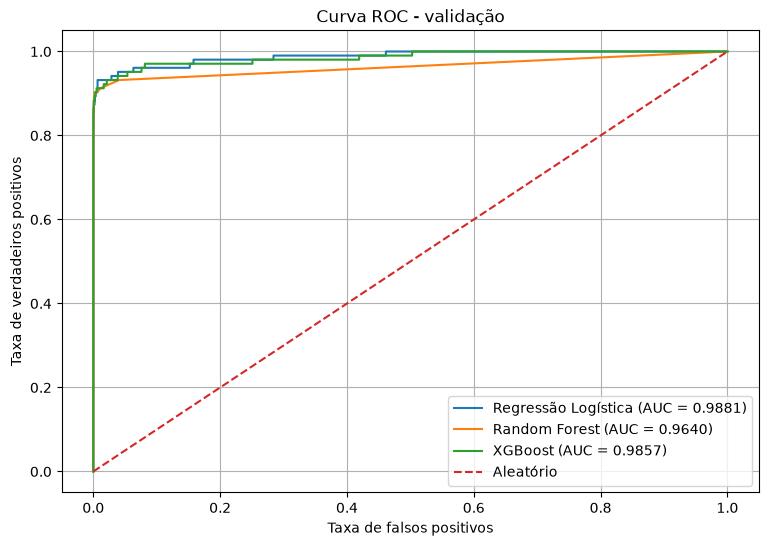

In [28]:
plt.figure(figsize=(9, 6))

for nome, modelo in modelos_validacao.items():
    probabilidades = modelo.predict_proba(X_validacao)[:, 1]

    fpr, tpr, _ = roc_curve(y_validacao, probabilidades)
    auc = roc_auc_score(y_validacao, probabilidades)

    plt.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Aleatório")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title("Curva ROC - validação")
plt.legend()
plt.grid()
plt.show()


### O que é AUC?

É a área abaixo da curva ROC.

- Próximo de 1: excelente capacidade de separar as duas classes.
- Próximo de 0,5: desempenho parecido com o acaso.

AUC não substitui recall nem precisão: um modelo pode ter AUC alto e precisão baixa para fraude.


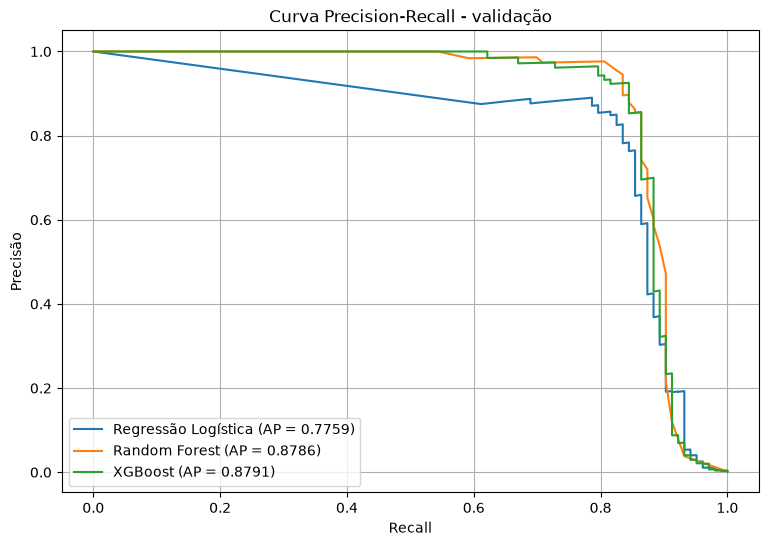

In [29]:
plt.figure(figsize=(9, 6))

for nome, modelo in modelos_validacao.items():
    probabilidades = modelo.predict_proba(X_validacao)[:, 1]

    precisao, recall, _ = precision_recall_curve(y_validacao, probabilidades)
    ap = average_precision_score(y_validacao, probabilidades)

    plt.plot(recall, precisao, label=f"{nome} (AP = {ap:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title("Curva Precision-Recall - validação")
plt.legend()
plt.grid()
plt.show()


### Comparando AUC e Average Precision

A tabela abaixo resume as curvas na validação. Ela serve para selecionar candidatos; a comparação definitiva no teste vem mais adiante, em uma única tabela.


In [30]:
df_validacao.set_index("Modelo")[["ROC-AUC", "Average Precision"]] \
    .sort_values(by="Average Precision", ascending=False) \
    .round(4)


,ROC-AUC,Average Precision
Modelo,,
XGBoost,0.9857,0.8791
Random Forest,0.9640,0.8786
Regressão Logística,0.9881,0.7759


### Busca de hiperparâmetros com GridSearchCV

Agora o `Pipeline` é otimizado diretamente: o prefixo `modelo__` indica que o parâmetro pertence ao classificador dentro do pipeline. Usamos validação cruzada estratificada e `scoring` com três métricas, escolhendo os melhores parâmetros pelo **recall**. Precisão e F1 são acompanhados para revelar o custo dessa escolha.


In [31]:
param_grid = {
    "modelo__n_estimators": [200, 300],
    "modelo__max_depth": [3, 4],
    "modelo__learning_rate": [0.05],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=construir_pipeline(
        XGBClassifier(
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=peso_fraude,
            eval_metric="logloss",
            random_state=42,
            n_jobs=1,
        )
    ),
    param_grid=param_grid,
    scoring={"recall": "recall", "precision": "precision", "f1": "f1"},
    refit="recall",
    cv=cv,
    n_jobs=-1,
    verbose=0,
)

grid.fit(X_treino, y_treino)

print("Melhores parâmetros:", grid.best_params_)
print("Melhor recall na validação cruzada:", round(grid.best_score_, 4))


Melhores parâmetros: {'modelo__learning_rate': 0.05, 'modelo__max_depth': 3, 'modelo__n_estimators': 200}
Melhor recall na validação cruzada: 0.8628


In [32]:
cv_resultados = pd.DataFrame({
    "n_estimators": [p["modelo__n_estimators"] for p in grid.cv_results_["params"]],
    "max_depth": [p["modelo__max_depth"] for p in grid.cv_results_["params"]],
    "recall": grid.cv_results_["mean_test_recall"],
    "precisão": grid.cv_results_["mean_test_precision"],
    "f1": grid.cv_results_["mean_test_f1"],
}).sort_values(by="recall", ascending=False).round(4)

cv_resultados


,n_estimators,max_depth,recall,precisão,f1
0,200,3,0.8628,0.4599,0.5991
1,300,3,0.8545,0.6929,0.7624
2,200,4,0.8462,0.7014,0.7650
3,300,4,0.8255,0.8210,0.8219


In [33]:
melhor_xgb = grid.best_estimator_

# probabilidades do modelo otimizado na validação (base para escolher o limiar)
probabilidades_grid = melhor_xgb.predict_proba(X_validacao)[:, 1]

print("Comparação na validação com o limiar padrão 0,5:")
pd.DataFrame([
    avaliar_modelo("XGBoost inicial", pipeline_xgb, X_validacao, y_validacao),
    avaliar_modelo("XGBoost GridSearchCV", melhor_xgb, X_validacao, y_validacao),
]).round(4)


Comparação na validação com o limiar padrão 0,5:


,Modelo,Acurácia,Precisão,Recall,F1-score,ROC-AUC,Average Precision
0,XGBoost inicial,0.9993,0.7672,0.8641,0.8128,0.9857,0.8791
1,XGBoost GridSearchCV,0.9966,0.3217,0.8932,0.4730,0.9864,0.8204


### O que a busca mostrou

O `GridSearchCV` escolheu `n_estimators=200`, `max_depth=3` e `learning_rate=0.05` pelo maior recall médio na validação cruzada (0,8628). As outras métricas médias mostram o custo dessa escolha: precisão de 0,4599 e F1 de 0,5991. A combinação com 300 árvores e profundidade 3 teve recall um pouco menor (0,8545), mas precisão maior (0,6929) e F1 de 0,7624.

Na validação externa, com o limiar padrão 0,5, o modelo otimizado tem mais recall que o XGBoost inicial, porém com precisão bem menor. Como as probabilidades dos dois modelos são diferentes, o próximo bloco escolhe o limiar usando as probabilidades do `melhor_xgb` — o modelo efetivamente usado como base na avaliação final.


### Ajuste do limiar de decisão (modelo otimizado)

O limiar é escolhido com as probabilidades do **XGBoost otimizado** (`melhor_xgb`) na validação. Isso é metodologicamente necessário: o GridSearchCV mudou os hiperparâmetros e, portanto, a distribuição das probabilidades. Usar um limiar selecionado com o modelo inicial seria incoerente com o modelo que vai para a avaliação final. Trata-se de seleção de limiar de decisão, não de calibração das probabilidades. O teste continua reservado.


In [34]:
# probabilidades do melhor XGBoost na validação
probabilidades_grid = melhor_xgb.predict_proba(X_validacao)[:, 1]
probabilidades_validacao = probabilidades_grid

# limiares que serão avaliados
limiares = [0.5, 0.4, 0.3, 0.2, 0.1]

resultados_limiar = []
for limiar in limiares:
    previsoes = (probabilidades_grid >= limiar).astype(int)
    matriz = confusion_matrix(y_validacao, previsoes)

    resultados_limiar.append({
        "Limiar": limiar,
        "Precisão": precision_score(
            y_validacao, previsoes, zero_division=0
        ),
        "Recall": recall_score(
            y_validacao, previsoes, zero_division=0
        ),
        "F1-score": f1_score(
            y_validacao, previsoes, zero_division=0
        ),
        "Falsos Positivos": matriz[0, 1],
        "Falsos Negativos": matriz[1, 0],
    })

df_threshold = pd.DataFrame(resultados_limiar)

# escolher o limiar com maior F1
LIMIAR_ESCOLHIDO = float(
    df_threshold
    .sort_values("F1-score", ascending=False)
    .iloc[0]["Limiar"]
)

print("Limiar escolhido com base no XGBoost otimizado:", LIMIAR_ESCOLHIDO)
df_threshold.sort_values(by="F1-score", ascending=False)


Limiar escolhido com base no XGBoost otimizado: 0.5


,Limiar,Precisão,Recall,F1-score,Falsos Positivos,Falsos Negativos
0,0.5,0.321678,0.893204,0.473008,194,11
1,0.4,0.243455,0.902913,0.383505,289,10
2,0.3,0.168761,0.912621,0.284848,463,9
3,0.2,0.108295,0.912621,0.193615,774,9
4,0.1,0.055077,0.932039,0.104009,1647,7


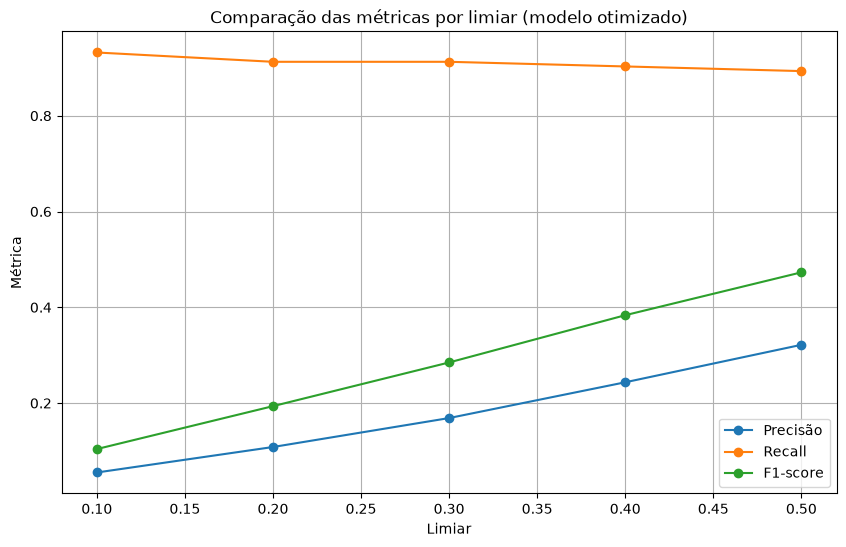

In [35]:
plt.figure(figsize=(10, 6))

plt.plot(df_threshold["Limiar"], df_threshold["Precisão"], marker="o", label="Precisão")
plt.plot(df_threshold["Limiar"], df_threshold["Recall"], marker="o", label="Recall")
plt.plot(df_threshold["Limiar"], df_threshold["F1-score"], marker="o", label="F1-score")

plt.xlabel("Limiar")
plt.ylabel("Métrica")
plt.title("Comparação das métricas por limiar (modelo otimizado)")
plt.legend()
plt.grid()
plt.show()


### Interpretação dos limiares

Com as probabilidades do XGBoost otimizado, o maior F1 **entre os cinco limiares avaliados** ocorre em **0,5** (0,4730), com precisão 0,3217, recall 0,8932, 194 falsos positivos e 11 falsos negativos. Uma busca mais detalhada poderia encontrar outro valor com desempenho superior. Ao baixar para 0,3, o recall sobe para 0,9126 (mais 2 fraudes entre 103), mas os falsos positivos saltam para 463 e o F1 cai para 0,2848. Em 0,1 o recall chega a 0,9320 com 1.647 falsos alertas. Como a precisão do modelo otimizado é baixa em todos os limiares, ele só faz sentido operacionalmente se a investigação de alertas for barata; caso contrário, o Random Forest da comparação final é mais adequado.


In [36]:
previsoes_validacao = (probabilidades_grid >= LIMIAR_ESCOLHIDO).astype(int)

print("Relatório na validação - XGBoost otimizado")
print(f"Limiar escolhido: {LIMIAR_ESCOLHIDO}")
print(classification_report(
    y_validacao, previsoes_validacao, target_names=["Normal", "Fraude"], zero_division=0
))
print("Matriz de confusão:")
print(confusion_matrix(y_validacao, previsoes_validacao))


Relatório na validação - XGBoost otimizado
Limiar escolhido: 0.5
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     59707
      Fraude       0.32      0.89      0.47       103

    accuracy                           1.00     59810
   macro avg       0.66      0.94      0.74     59810
weighted avg       1.00      1.00      1.00     59810

Matriz de confusão:
[[59513   194]
 [   11    92]]


### Comparando class_weight, undersampling e oversampling

Para isolar o efeito de cada estratégia, usamos a regressão logística nos três casos e comparamos pelo recall da classe fraude na validação:

- `class_weight="balanced"`: penaliza erros na classe minoritária sem alterar os dados.
- **Undersampling**: reduz a classe majoritária ao tamanho da minoritária.
- **Oversampling**: replica a classe minoritária até equilibrar as quantidades.


In [37]:
# separando as linhas do treino interno por classe
normais = X_treino.loc[y_treino == 0]
fraudes = X_treino.loc[y_treino == 1]

# undersampling: amostrar a maioria sem reposição até ficar do tamanho da minoria
normais_under = normais.sample(n=len(fraudes), random_state=42)
X_under = pd.concat([normais_under, fraudes])
y_under = pd.concat([
    y_treino.loc[normais_under.index],
    y_treino.loc[fraudes.index],
])

pipeline_under = construir_pipeline(
    LogisticRegression(max_iter=1000, random_state=42)
)
pipeline_under.fit(X_under, y_under)

# oversampling: replicar a minoria com reposição até ficar do tamanho da maioria
fraudes_over = fraudes.sample(n=len(normais), replace=True, random_state=42)
X_over = pd.concat([normais, fraudes_over])
y_over = pd.concat([
    y_treino.loc[normais.index],
    pd.Series(1, index=fraudes_over.index),
])

pipeline_over = construir_pipeline(
    LogisticRegression(max_iter=1000, random_state=42)
)
pipeline_over.fit(X_over, y_over)

print("Undersampling:", X_under.shape, "fraudes:", int(y_under.sum()))
print("Oversampling:", X_over.shape, "fraudes:", int(y_over.sum()))


Undersampling: (482, 30) fraudes: 241
Oversampling: (278626, 30) fraudes: 139313


In [38]:
estrategias = {
    "class_weight='balanced'": pipeline_lr,
    "Undersampling": pipeline_under,
    "Oversampling": pipeline_over,
}

df_balanceamento = pd.DataFrame([
    avaliar_modelo(nome, modelo, X_validacao, y_validacao, LIMIAR_ESCOLHIDO)
    for nome, modelo in estrategias.items()
])

df_balanceamento.sort_values(by="Recall", ascending=False).round(4)


,Modelo,Acurácia,Precisão,Recall,F1-score,ROC-AUC,Average Precision
0,class_weight='balanced',0.9780,0.0683,0.932,0.1272,0.9881,0.7759
1,Undersampling,0.9798,0.0738,0.932,0.1368,0.9872,0.7445
2,Oversampling,0.9779,0.0681,0.932,0.1269,0.9882,0.7715


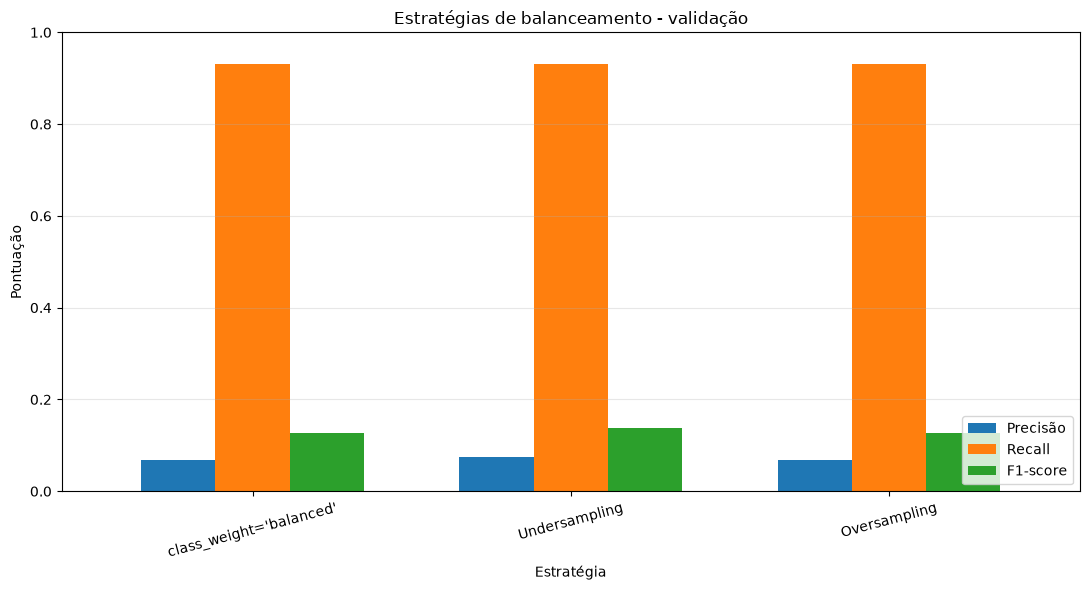

In [39]:
df_balanceamento.set_index("Modelo")[["Precisão", "Recall", "F1-score"]] \
    .plot(kind="bar", figsize=(11, 6), ylim=(0, 1), width=0.7)

plt.title("Estratégias de balanceamento - validação")
plt.ylabel("Pontuação")
plt.xlabel("Estratégia")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretação do balanceamento

As três estratégias tiveram o mesmo recall na validação (0,9320). O undersampling apresentou F1 ligeiramente maior (0,1368) e o oversampling ficou bem próximo do `class_weight`. Como o recall não mudou e o `class_weight` não exige manipular a base — evitando perda de dados no undersampling e repetição de fraudes no oversampling — ele continua sendo a opção mais simples. Vale observar que a precisão é baixa em todos os casos: para o negócio, o limiar é a alavanca mais poderosa para controlar falsos alertas.


### Modelos finais e avaliação única no teste

Os modelos abaixo são reajustados com **todo** o conjunto de treino (`X_train`) e avaliados **uma única vez** em `X_test`, usando o mesmo limiar escolhido na validação. Esta é a tabela oficial de comparação: as tabelas anteriores eram apenas de seleção, na validação. Assim não existem dois conjuntos de números aparentemente conflitantes para o mesmo modelo.


In [40]:
peso_fraude_final = (y_train == 0).sum() / (y_train == 1).sum()

modelo_xgb_final = clone(grid.best_estimator_)
modelo_xgb_final.named_steps["modelo"].set_params(scale_pos_weight=peso_fraude_final)

modelos_finais = {
    "Regressão Logística": construir_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
    ),
    "Random Forest": construir_pipeline(
        RandomForestClassifier(
            n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1
        )
    ),
    "XGBoost (GridSearchCV)": modelo_xgb_final,
}

for nome, modelo in modelos_finais.items():
    modelo.fit(X_train, y_train)
    print("Modelo ajustado:", nome)


Modelo ajustado: Regressão Logística


Modelo ajustado: Random Forest


Modelo ajustado: XGBoost (GridSearchCV)


In [41]:
df_resultados = pd.DataFrame([
    avaliar_modelo(nome, modelo, X_test, y_test, LIMIAR_ESCOLHIDO)
    for nome, modelo in modelos_finais.items()
])

df_resultados_final = df_resultados.sort_values(by="F1-score", ascending=False).round(4)
print(f"Comparação oficial no teste (limiar = {LIMIAR_ESCOLHIDO}):")
df_resultados_final


Comparação oficial no teste (limiar = 0.5):


,Modelo,Acurácia,Precisão,Recall,F1-score,ROC-AUC,Average Precision
1,Random Forest,0.9994,0.9098,0.7500,0.8222,0.9429,0.8101
2,XGBoost (GridSearchCV),0.9955,0.2577,0.8514,0.3956,0.9728,0.7514
0,Regressão Logística,0.9780,0.0648,0.8716,0.1206,0.9677,0.7022


In [42]:
modelo_escolhido = modelos_finais["XGBoost (GridSearchCV)"]

probabilidades_teste = modelo_escolhido.predict_proba(X_test)[:, 1]
previsoes_teste = (probabilidades_teste >= LIMIAR_ESCOLHIDO).astype(int)

print("Relatório de classificação - XGBoost final no teste")
print(classification_report(
    y_test, previsoes_teste, target_names=["Normal", "Fraude"], zero_division=0
))
print("Matriz de confusão:")
print(confusion_matrix(y_test, previsoes_teste))


Relatório de classificação - XGBoost final no teste
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     85295
      Fraude       0.26      0.85      0.40       148

    accuracy                           1.00     85443
   macro avg       0.63      0.92      0.70     85443
weighted avg       1.00      1.00      1.00     85443

Matriz de confusão:
[[84932   363]
 [   22   126]]


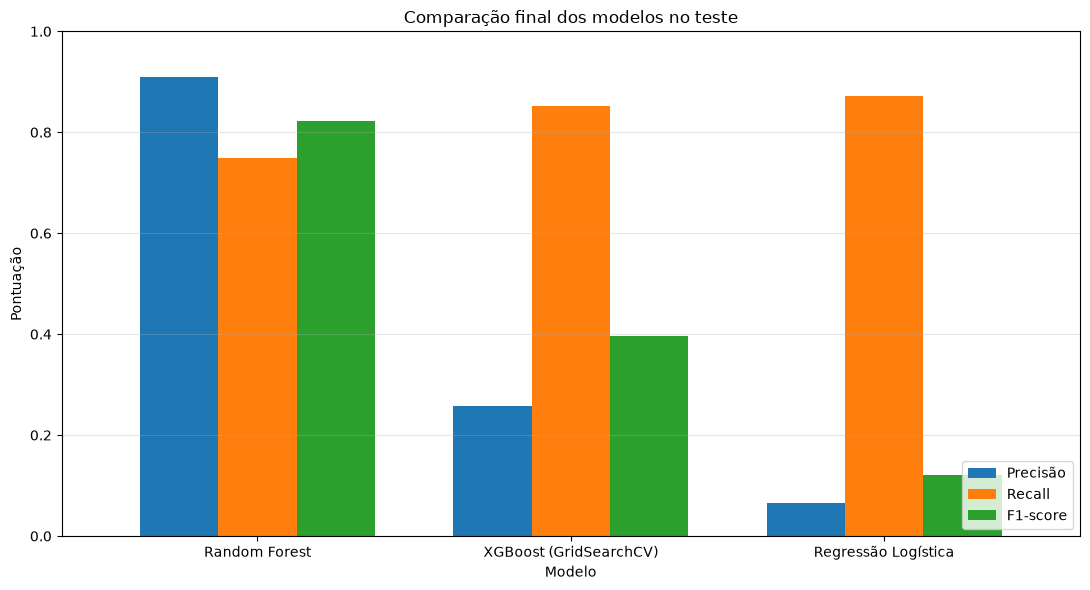

In [43]:
df_grafico = df_resultados_final.set_index("Modelo")[["Precisão", "Recall", "F1-score"]]

df_grafico.plot(kind="bar", figsize=(11, 6), ylim=(0, 1), width=0.75)

plt.title("Comparação final dos modelos no teste")
plt.ylabel("Pontuação")
plt.xlabel("Modelo")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### Narrativa unificada dos resultados

Esta é a única tabela de comparação no teste. As tabelas anteriores foram calculadas na validação e serviram para escolher hiperparâmetros, selecionar o limiar de decisão com as probabilidades do XGBoost otimizado e comparar estratégias de balanceamento; não competem com estes números.

No teste, o **Random Forest** teve o melhor F1 (0,8222), a maior precisão (0,9098) e o maior AP (0,8101), com recall de 0,7500 — ou seja, menos alertas falsos, mas 37 fraudes deixadas passar. O **XGBoost selecionado pelo recall** no GridSearchCV capturou 126 de 148 fraudes (recall 0,8514), porém com precisão de apenas 0,2577 e F1 de 0,3956: 363 transações normais foram investigadas. A **Regressão Logística** teve recall de 0,8716, mas precisão de 0,0648, inviável na prática.

A conclusão não é "qual algoritmo é melhor", e sim qual custo a operação aceita. Se investigar falsos alertas é caro, o Random Forest é a melhor escolha; se deixar fraudes passar é mais caro, o XGBoost com recall maior é preferível, desde que a equipe absorva o volume de revisões. O limiar pode ser ajustado para mover o modelo ao longo desse trade-off sem treinar de novo.


In [44]:
import shap

# o SHAP precisa do modelo e dos dados já transformados pelo scaler do Pipeline
X_test_transformado = pd.DataFrame(
    modelo_escolhido.named_steps["scaler"].transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

explainer = shap.TreeExplainer(modelo_escolhido.named_steps["modelo"])
shap_values = explainer.shap_values(X_test_transformado)


D:\Estudos\Formacao\instituicao\DIO\SQL_DATABASE\dados\deteccao-fraude-cartao\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


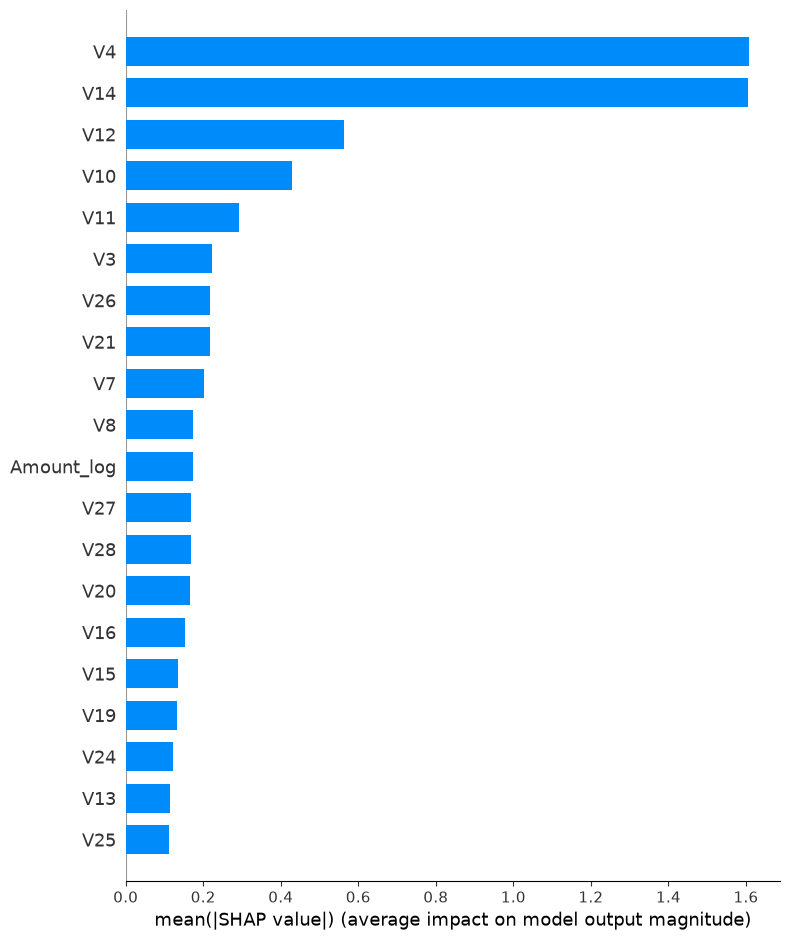

In [ ]:
# Visualizando a importância das features com SHAP
shap.summary_plot(
    shap_values, X_test_transformado, feature_names=X_test.columns, plot_type="bar"
)


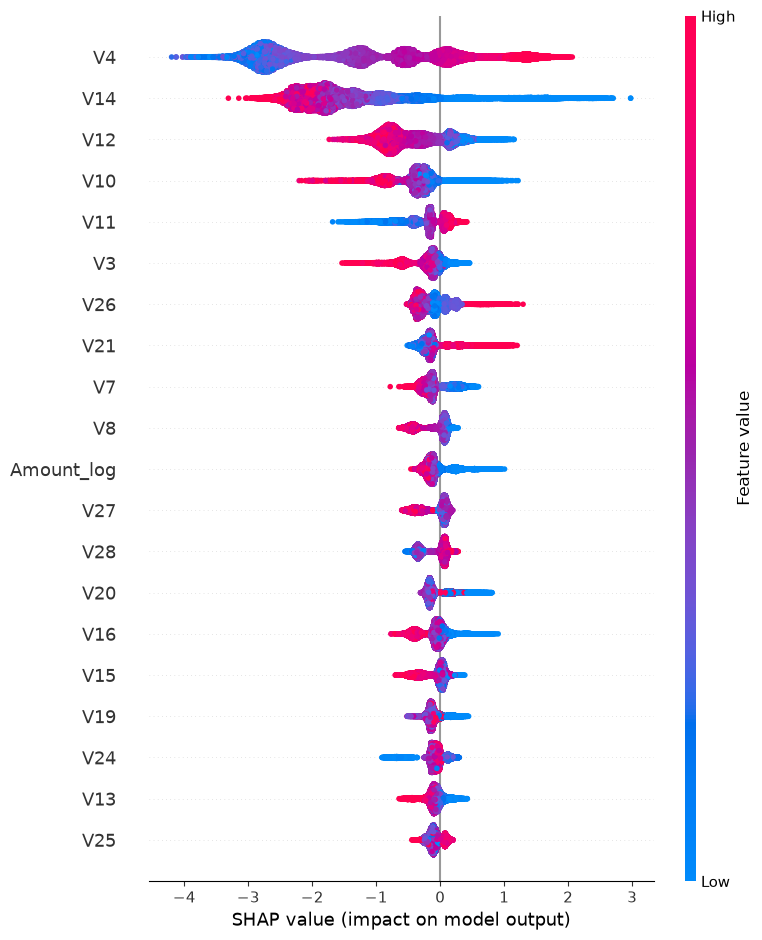

In [ ]:
# Visualizando a importância das features com SHAP (gráfico de dispersão)
shap.summary_plot(shap_values, X_test_transformado, feature_names=X_test.columns)


In [47]:
importancia_shap = pd.DataFrame({
    "Variável": X_test.columns,
    "Importância SHAP": np.abs(shap_values).mean(axis=0),
})

importancia_shap = importancia_shap.sort_values(
    by="Importância SHAP", ascending=False
)

display(importancia_shap.head(10))


,Variável,Importância SHAP
4,V4,1.607394
14,V14,1.605187
12,V12,0.563269
10,V10,0.427749
11,V11,0.292075
3,V3,0.223274
26,V26,0.218689
21,V21,0.217920
7,V7,0.202537
8,V8,0.173853


### Interpretação da importância SHAP

As variáveis com maior contribuição média aparecem no topo da tabela. Vale lembrar que `V1` a `V28` são componentes PCA: não é possível atribuir a elas um significado financeiro direto. A importância média mostra **quanto** cada variável pesa, mas não **em qual direção** — para isso usamos o gráfico beeswarm.


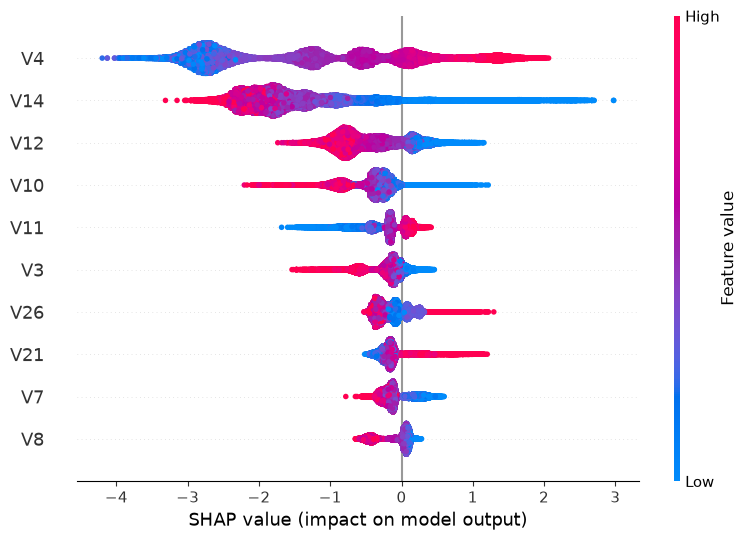

In [ ]:
# Visualizando a importância das features com SHAP (gráfico de dispersão)
shap.summary_plot(
    shap_values, X_test_transformado, feature_names=X_test.columns, max_display=10
)


### Direção das contribuições

No beeswarm, cada ponto é uma transação: a posição horizontal mostra se aquela variável empurrou a previsão para mais ou menos fraude, e a cor indica o valor da variável. Nesta rodada, **V4** e **V14** aparecem com as maiores contribuições médias, seguidas de V12, V10 e V11; componentes como V26, V21, V7 e V8 também aparecem entre as dez primeiras. Como V1–V28 são componentes PCA, a leitura é sobre o comportamento do classificador, não sobre causas da fraude.
